# LDA topics for presentation (K = 12)
Use the saved K=12 results from the two separate corpora. Topic names are short interpretations of the keywords.

## 1. Load the results and name the topics

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.ticker import FuncFormatter

project = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "notebook").is_dir() and (p / "data").is_dir())
results = project / "data" / "analysis_results"
output = results / "lda_k12_presentation"
(project / "data" / "generated_figures" / output.relative_to(project / "data" / "analysis_results")).mkdir(parents=True, exist_ok=True)
(project / "data" / "model_cache" / output.relative_to(project / "data" / "analysis_results")).mkdir(parents=True, exist_ok=True)
output.mkdir(parents=True, exist_ok=True)

names = {
    "official_media": [
        "Bride-price returns", "Marriage choices", "Fertility policy",
        "Marriage registration", "Rural bride-price reform", "Wedding reform",
        "Youth dating", "Divorce disputes", "Domestic violence",
        "Matchmaking services", "Romance scams", "Family mediation",
    ],
    "weibo_posts": [
        "Marriage choices", "Gender and fertility", "Dating feelings",
        "Bride price", "Marriage hopes", "Marriage pressure",
        "Relationship feelings", "Daily life (mixed)", "Matchmaking (mixed)",
        "Divorce", "Work and marriage", "Children and family",
    ],
}

def load_topics(corpus):
    folder = results / f"lda_{corpus}"
    words = pd.read_csv(folder / "k12_top10_keywords.csv")
    shares = pd.read_csv(folder / "k12_topic_prevalence.csv")
    table = words.merge(shares[["topic", "prevalence_pct"]], on="topic")
    table.insert(1, "interpretation", names[corpus])
    table.insert(0, "corpus", corpus)
    return table

official = load_topics("official_media")
weibo = load_topics("weibo_posts")
pd.concat([official, weibo], ignore_index=True).to_csv(
    output / "k12_topics_with_interpretations.csv", index=False, encoding="utf-8-sig"
)
print("Loaded 12 topics for each corpus.")


Loaded 12 topics for each corpus.


## 2. Make the topic tables
Each row shows one topic, its top 10 Chinese words, and a short English interpretation.

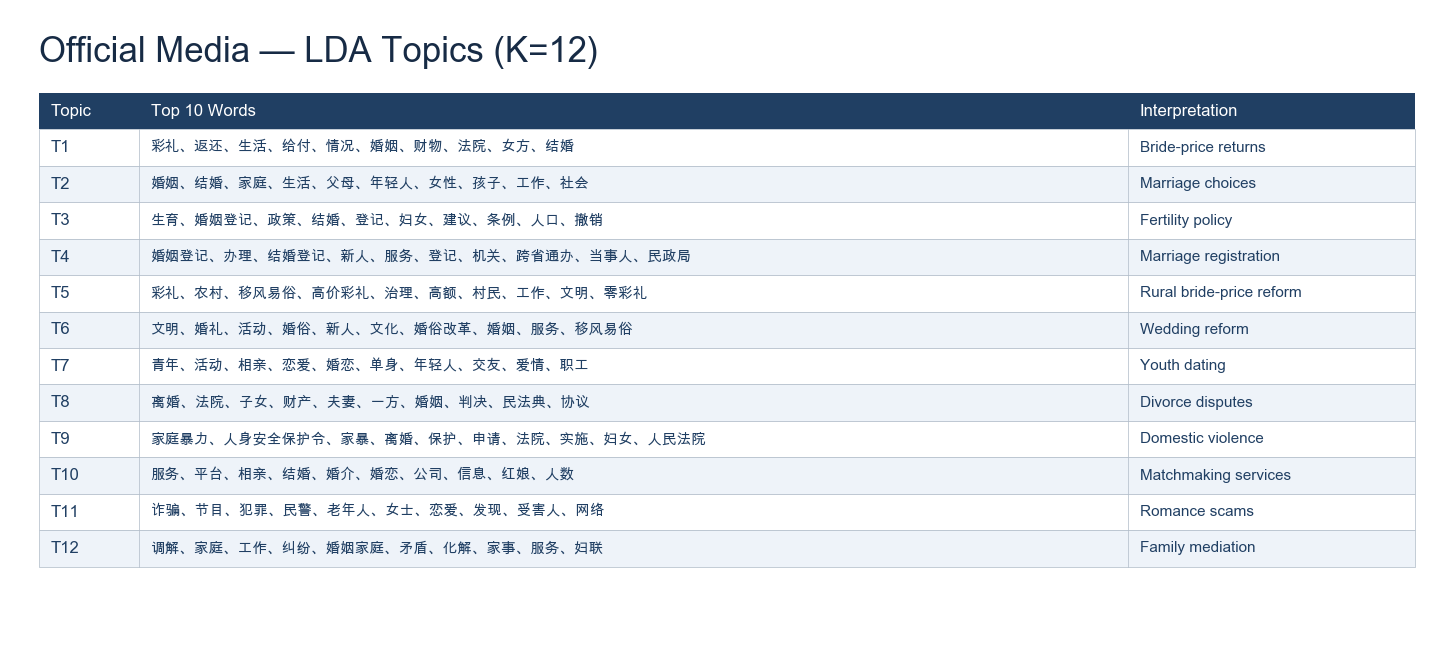

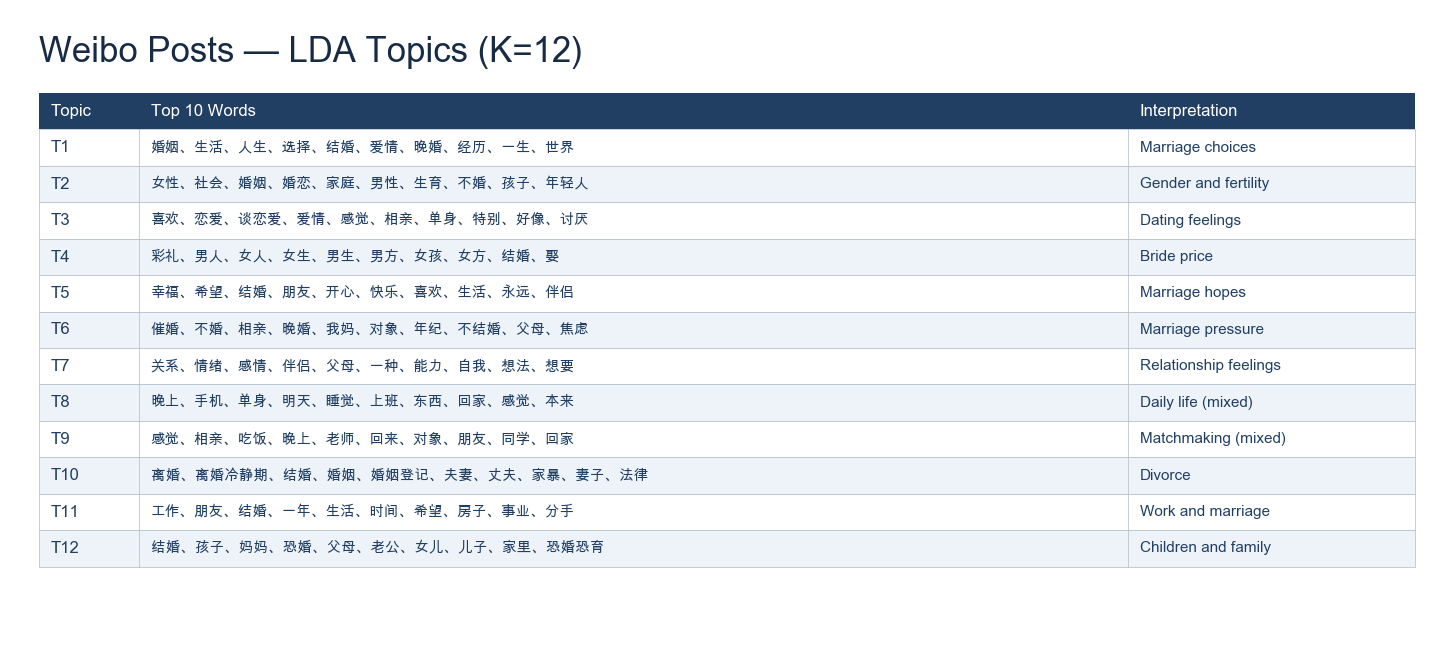

In [2]:
plt.rcParams["font.family"] = "Arial Unicode MS"

def draw_topic_table(table, title, path):
    fig, ax = plt.subplots(figsize=(18.5, 8.3), facecolor="white")
    ax.axis("off")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.text(0.02, 0.96, title, fontsize=25, fontweight="bold",
            va="top", color="#172b45", transform=ax.transAxes)
    x0, y_top, width, row_h = 0.02, 0.87, 0.96, 0.057
    edges = [x0, 0.09, 0.78, x0 + width]
    ax.add_patch(Rectangle((x0, y_top - row_h), width, row_h,
                           facecolor="#203f63", transform=ax.transAxes))
    for x, label in zip([edge + 0.008 for edge in edges[:3]],
                        ["Topic", "Top 10 Words", "Interpretation"]):
        ax.text(x, y_top - row_h / 2, label, va="center", fontsize=12,
                fontweight="bold", color="white", transform=ax.transAxes)

    for i, row in table.sort_values("topic").reset_index(drop=True).iterrows():
        y = y_top - (i + 2) * row_h
        ax.add_patch(Rectangle((x0, y), width, row_h,
                               facecolor="#eef3f9" if i % 2 else "#ffffff",
                               edgecolor="#b5c0cc", linewidth=0.55, transform=ax.transAxes))
        for edge in edges[1:-1]:
            ax.plot([edge, edge], [y, y + row_h], color="#b5c0cc",
                    linewidth=0.55, transform=ax.transAxes)
        words = "、".join(str(row[f"keyword_{j}"]) for j in range(1, 11))
        ax.text(edges[0] + 0.008, y + row_h / 2, f"T{row['topic']}",
                va="center", fontsize=12, fontweight="bold", color="#203f63", transform=ax.transAxes)
        ax.text(edges[1] + 0.008, y + row_h / 2, words,
                va="center", fontsize=10.5, color="#203f63", transform=ax.transAxes)
        ax.text(edges[2] + 0.008, y + row_h / 2, row["interpretation"],
                va="center", fontsize=11, color="#203f63", transform=ax.transAxes)
    fig.savefig(path, dpi=180, facecolor="white", bbox_inches="tight")
    plt.show()

draw_topic_table(official, "Official Media — LDA Topics (K=12)", (project / "data" / "generated_figures" / output.relative_to(project / "data" / "analysis_results")) / "official_topics_table.png")
draw_topic_table(weibo, "Weibo Posts — LDA Topics (K=12)", (project / "data" / "generated_figures" / output.relative_to(project / "data" / "analysis_results")) / "weibo_topics_table.png")


## 3. Compare topic prevalence
Each side ranks its own topics by average topic probability. The two topic models were fitted separately.

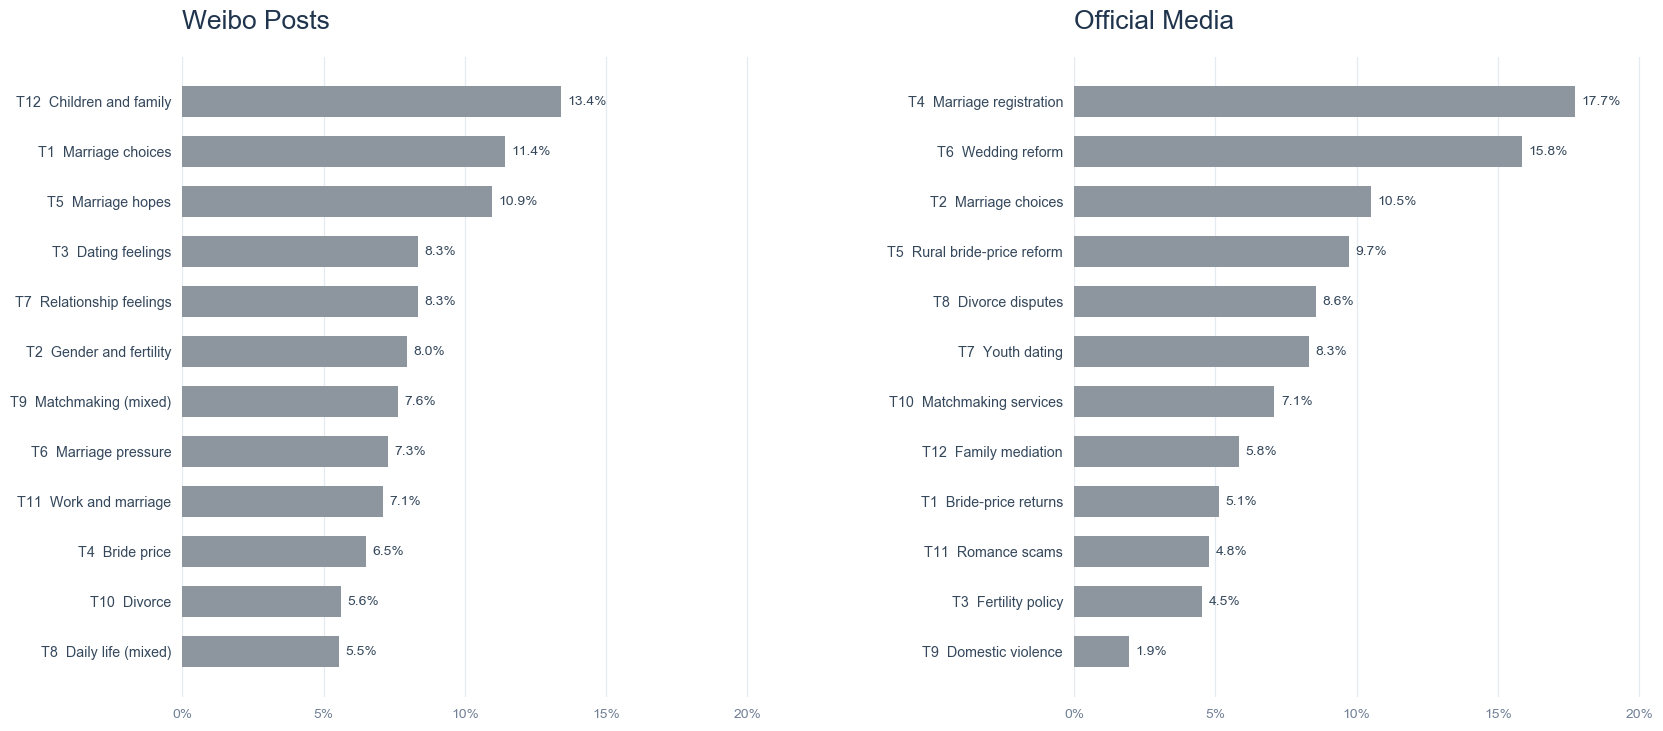

Saved the topic tables and comparison chart in: /Users/jingwenzhai/Desktop/Fightin Words/结果/lda_k12_presentation


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(18.5, 8.1), facecolor="white")

for ax, table, title in [
    (axes[0], weibo, "Weibo Posts"),
    (axes[1], official, "Official Media"),
]:
    ranked = table.sort_values("prevalence_pct", ascending=False).reset_index(drop=True)
    shown = ranked.iloc[::-1]
    labels = [f"T{row.topic}  {row.interpretation}" for row in shown.itertuples()]
    bars = ax.barh(labels, shown["prevalence_pct"], color="#8d959f", height=0.63)
    ax.set_xlim(0, 20.5)
    ax.set_title(title, loc="left", fontsize=19, fontweight="bold", color="#20354d", pad=20)
    ax.set_facecolor("#ffffff")
    ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:.0f}%"))
    ax.set_xticks([0, 5, 10, 15, 20])
    ax.grid(axis="x", color="#e4eaf0", linewidth=0.9)
    ax.set_axisbelow(True)
    ax.tick_params(axis="y", length=0, labelsize=10.3, pad=8, colors="#34475b")
    ax.tick_params(axis="x", length=0, labelsize=10, pad=9, colors="#718095")
    for spine in ax.spines.values():
        spine.set_visible(False)
    for bar, value in zip(bars, shown["prevalence_pct"]):
        ax.text(value + 0.23, bar.get_y() + bar.get_height() / 2,
                f"{value:.1f}%", va="center", fontsize=10,
                fontweight="bold", color="#34475b")

fig.subplots_adjust(left=0.185, right=0.98, top=0.89, bottom=0.10, wspace=0.54)
fig.savefig((project / "data" / "generated_figures" / output.relative_to(project / "data" / "analysis_results")) / "topic_prevalence_comparison.png", dpi=180,
            facecolor=fig.get_facecolor(), bbox_inches="tight")
plt.show()
print("Saved the topic tables and comparison chart in:", output)


## 4. Compare all Weibo trends in one chart
Each color represents one topic within the Weibo model. The y-axis shows annual mean topic probability.

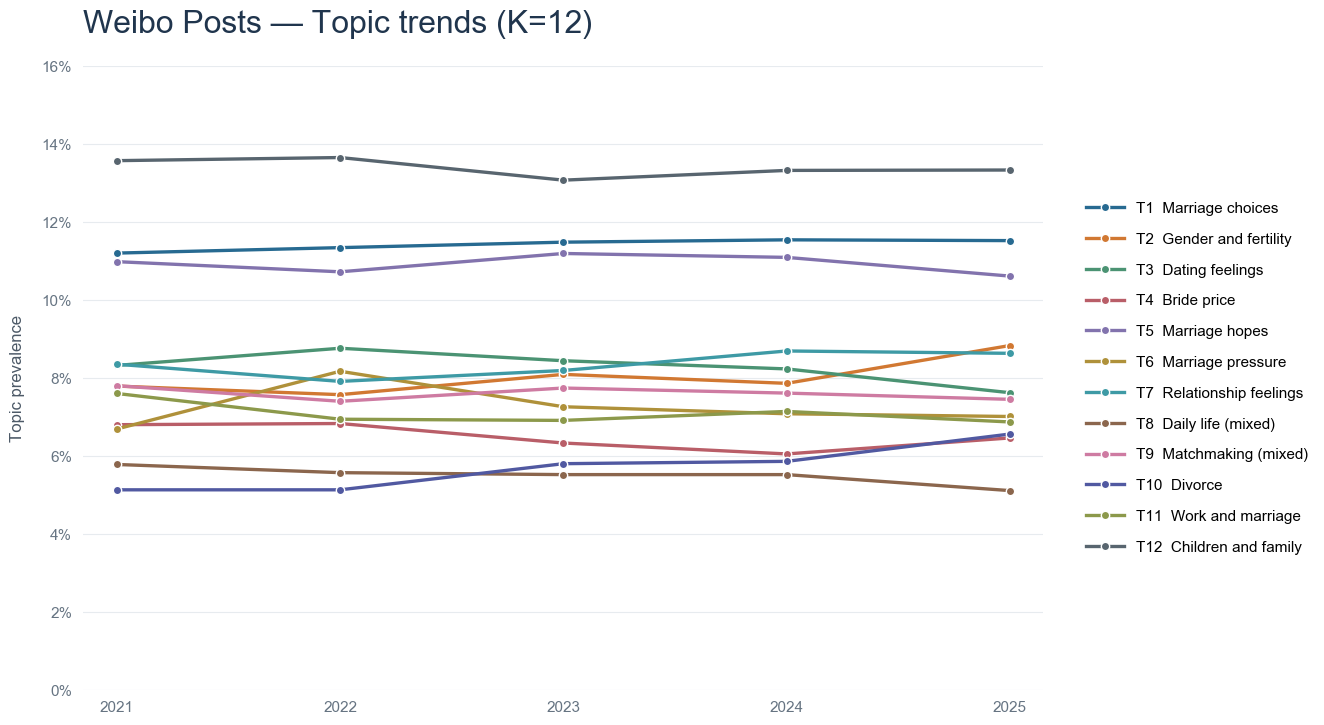

In [4]:
yearly = pd.read_csv(results / "lda_weibo_posts" / "k12_topic_by_year.csv")
colors = ["#276A91", "#D17832", "#4B9373", "#B95E68", "#8273AD", "#AF913A",
          "#3E9AA5", "#8B664D", "#CE7BA2", "#5159A1", "#8C994B", "#58656F"]
fig, ax = plt.subplots(figsize=(15, 8), facecolor="white")

for topic, color in enumerate(colors, start=1):
    values = yearly[yearly["topic"] == topic].sort_values("year")
    ax.plot(values["year"], values["prevalence_pct"], color=color,
            linewidth=2.4, marker="o", markersize=6, markeredgecolor="white",
            label=f"T{topic}  {names['weibo_posts'][topic - 1]}")

ax.set_title("Weibo Posts — Topic trends (K=12)", loc="left", fontsize=23,
             fontweight="bold", color="#20354d", pad=24)
ax.set_xlim(2020.85, 2025.15)
ax.set_ylim(0, 16)
ax.set_xticks(range(2021, 2026))
ax.set_yticks(range(0, 17, 2))
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:.0f}%"))
ax.set_ylabel("Topic prevalence", fontsize=12, color="#4c5967", labelpad=12)
ax.grid(axis="y", color="#e7ebef", linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(axis="both", length=0, labelsize=11, colors="#667482", pad=8)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.legend(loc="center left", bbox_to_anchor=(1.03, 0.5), frameon=False,
          fontsize=11, labelspacing=1.1, handlelength=2.5)
fig.subplots_adjust(left=0.08, right=0.72, top=0.88, bottom=0.10)
fig.savefig((project / "data" / "generated_figures" / output.relative_to(project / "data" / "analysis_results")) / "weibo_topic_trends_combined.png", dpi=220,
            facecolor="white", bbox_inches="tight")
plt.show()


## 5. Plot interpretable changes in official media
Select four themes for their relevance to marriage discourse and overall direction: rural bride-price reform and wedding reform rise overall; marriage choices and fertility policy decline overall. Only marriage choices declines every year. The other patterns include fluctuations.

Each panel uses the same 0–25% scale and shows annual mean topic probabilities. Selection is exploratory, not a statistical significance test. These shares describe relative attention in the collected media sample, not public attitudes or policy effects.

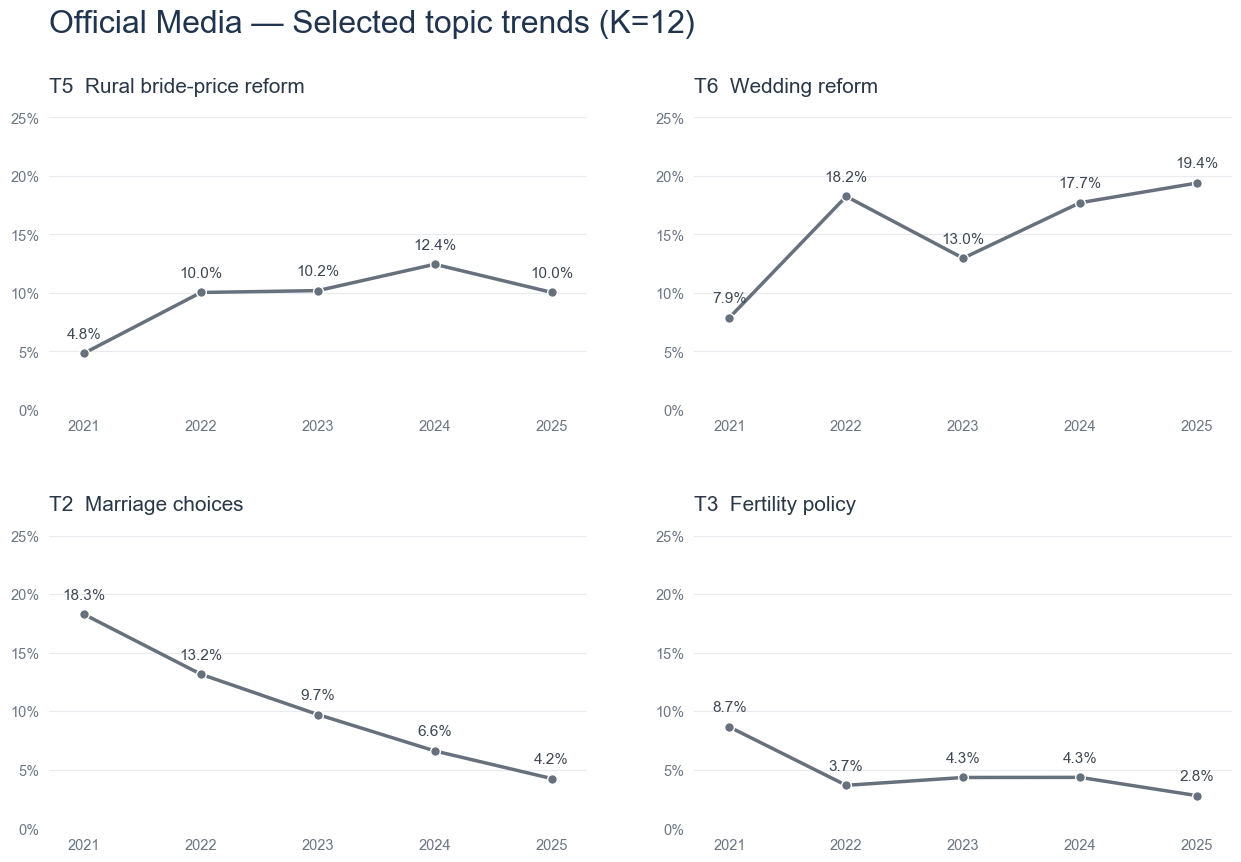

In [5]:
yearly = pd.read_csv(results / "lda_official_media" / "k12_topic_by_year.csv")
selected_topics = [5, 6, 2, 3]
fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True, sharey=True, facecolor="white")

for topic, ax in zip(selected_topics, axes.flat):
    values = yearly[yearly["topic"] == topic].sort_values("year")
    ax.plot(values["year"], values["prevalence_pct"], color="#67717d",
            linewidth=2.5, marker="o", markersize=7, markeredgecolor="white")
    for point in values.itertuples():
        ax.annotate(f"{point.prevalence_pct:.1f}%", (point.year, point.prevalence_pct),
                    xytext=(0, 11), textcoords="offset points", ha="center",
                    fontsize=11, color="#3d4753")
    ax.set_title(f"T{topic}  {names['official_media'][topic - 1]}", loc="left",
                 fontsize=15, color="#293746", pad=18)
    ax.set_xlim(2020.7, 2025.3)
    ax.set_ylim(0, 25)
    ax.set_xticks(range(2021, 2026))
    ax.set_yticks([0, 5, 10, 15, 20, 25])
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:.0f}%"))
    ax.grid(axis="y", color="#e7ebef", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(axis="both", length=0, labelsize=10.5, colors="#6b7683",
                   labelbottom=True, labelleft=True, pad=7)
    for spine in ax.spines.values():
        spine.set_visible(False)

fig.suptitle("Official Media — Selected topic trends (K=12)", x=0.07, y=0.98,
             ha="left", fontsize=23, fontweight="bold", color="#20354d")
fig.subplots_adjust(left=0.07, right=0.98, top=0.86, bottom=0.07, wspace=0.20, hspace=0.43)
fig.savefig((project / "data" / "generated_figures" / output.relative_to(project / "data" / "analysis_results")) / "official_selected_topic_trends.png", dpi=220,
            facecolor="white", bbox_inches="tight")
plt.show()
